# Performance across real and synthetic AG News mixtures

This notebook compares the five saved one-epoch DistilBERT experiments. It reuses their recorded evaluations on the same original 7,600-row real test set and does not retrain models. The 0% synthetic run is the directly comparable real-only baseline. Trainer runtime was recorded, but peak GPU memory was not measured during the original runs; it is reported as unavailable rather than estimated.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
SOURCE_DIR = ROOT / 'results' / 'mixture_training'
RESULTS_DIR = ROOT / 'results' / 'mixture_comparison'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PERCENTAGES = [0, 25, 50, 75, 100]
LABELS = ['World', 'Sports', 'Business', 'Sci/Tech']

rows = []
for percentage in PERCENTAGES:
    name = f'synthetic_{percentage:03d}'
    record = json.loads((SOURCE_DIR / name / 'metrics.json').read_text(encoding='utf-8'))
    history = json.loads((SOURCE_DIR / name / 'training_history.json').read_text(encoding='utf-8'))
    model_dir = ROOT / record['model_dir']
    assert (model_dir / 'model.safetensors').exists(), f'Missing model: {name}'
    assert record['label_names'] == LABELS
    assert sum(sum(line) for line in record['test_confusion_matrix']) == 7600
    assert all(record['test_per_class'][label]['support'] == 1900 for label in LABELS)
    runtime = next((item['train_runtime'] for item in reversed(history) if 'train_runtime' in item), None)
    assert runtime is not None, f'Missing training runtime: {name}'
    metrics = record['summary_row']
    rows.append({
        'synthetic_percentage': percentage,
        'real_count': metrics['real_count'],
        'synthetic_count': metrics['synthetic_count'],
        'training_runtime_seconds': runtime,
        'gpu_peak_memory_mib': 'not recorded',
        'test_accuracy': metrics['test_accuracy'],
        'test_macro_precision': metrics['test_macro_precision'],
        'test_macro_recall': metrics['test_macro_recall'],
        'test_macro_f1': metrics['test_macro_f1'],
        **{f"recall_{label.lower().replace('/', '_')}": record['test_per_class'][label]['recall'] for label in LABELS},
    })

comparison = pd.DataFrame(rows).sort_values('synthetic_percentage').reset_index(drop=True)
baseline = comparison.loc[comparison['synthetic_percentage'] == 0].iloc[0]
comparison['accuracy_change_pp_vs_real'] = 100 * (comparison['test_accuracy'] - baseline['test_accuracy'])
comparison['macro_f1_change_pp_vs_real'] = 100 * (comparison['test_macro_f1'] - baseline['test_macro_f1'])
comparison.to_csv(RESULTS_DIR / 'comparison.csv', index=False)
display(comparison.round(4))

,synthetic_percentage,real_count,synthetic_count,training_runtime_seconds,gpu_peak_memory_mib,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,recall_world,recall_sports,recall_business,recall_sci_tech,accuracy_change_pp_vs_real,macro_f1_change_pp_vs_real
0,0,8000,0,68.2369,not recorded,0.9075,0.9072,0.9075,0.9073,0.8953,0.9826,0.8605,0.8916,0.0000,0.0000
1,25,6000,2000,65.0015,not recorded,0.9087,0.9085,0.9087,0.9085,0.8995,0.9789,0.8584,0.8979,0.1184,0.1272
2,50,4000,4000,64.9044,not recorded,0.8997,0.9006,0.8997,0.8998,0.8742,0.9826,0.8816,0.8605,-0.7763,-0.7494
3,75,2000,6000,66.0150,not recorded,0.8908,0.8905,0.8908,0.8906,0.8805,0.9758,0.8526,0.8542,-1.6711,-1.6635
4,100,0,8000,60.3941,not recorded,0.7820,0.8115,0.7820,0.7641,0.9005,0.9842,0.8500,0.3932,-12.5526,-14.3119


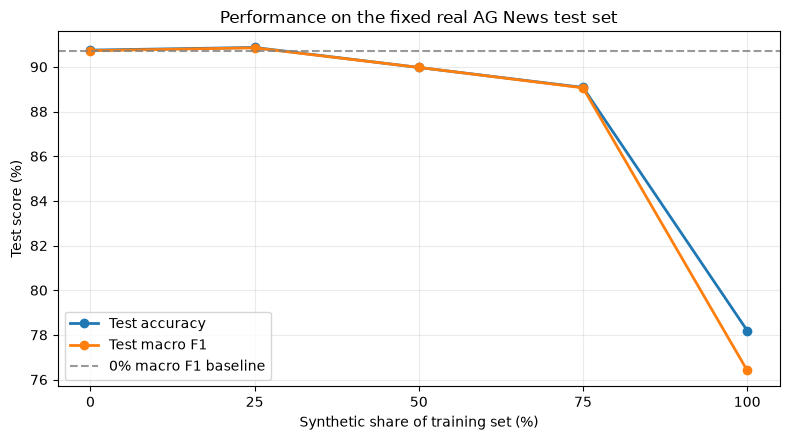

In [2]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = comparison['synthetic_percentage']
ax.plot(x, 100 * comparison['test_accuracy'], marker='o', linewidth=2, label='Test accuracy')
ax.plot(x, 100 * comparison['test_macro_f1'], marker='o', linewidth=2, label='Test macro F1')
ax.axhline(100 * baseline['test_macro_f1'], color='gray', linestyle='--', alpha=0.8, label='0% macro F1 baseline')
ax.set(xlabel='Synthetic share of training set (%)', ylabel='Test score (%)', title='Performance on the fixed real AG News test set')
ax.set_xticks(PERCENTAGES)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'performance_vs_synthetic.png', dpi=160)
plt.show()

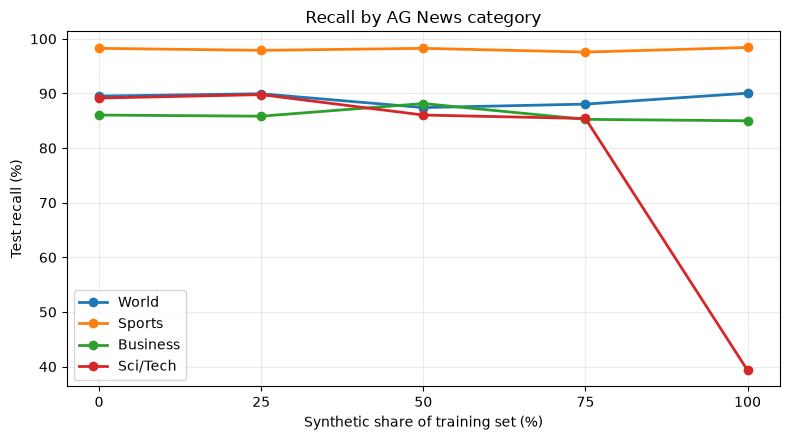

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for label in LABELS:
    column = f"recall_{label.lower().replace('/', '_')}"
    ax.plot(x, 100 * comparison[column], marker='o', linewidth=2, label=label)
ax.set(xlabel='Synthetic share of training set (%)', ylabel='Test recall (%)', title='Recall by AG News category')
ax.set_xticks(PERCENTAGES)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'per_class_recall.png', dpi=160)
plt.show()

In [4]:
synthetic_runs = comparison[comparison['synthetic_percentage'] > 0]
best = synthetic_runs.loc[synthetic_runs['test_macro_f1'].idxmax()]
pure_synthetic = comparison.loc[comparison['synthetic_percentage'] == 100].iloc[0]
findings = {
    'comparison_basis': 'Five saved models evaluated on the same 7,600 original real AG News test samples',
    'retrained': False,
    'best_observed_synthetic_percentage_by_test_macro_f1': int(best['synthetic_percentage']),
    'best_observed_test_macro_f1': float(best['test_macro_f1']),
    'best_vs_real_only_macro_f1_percentage_points': float(best['macro_f1_change_pp_vs_real']),
    'pure_synthetic_vs_real_only_macro_f1_percentage_points': float(pure_synthetic['macro_f1_change_pp_vs_real']),
    'pure_synthetic_sci_tech_recall': float(pure_synthetic['recall_sci_tech']),
    'gpu_peak_memory_status': 'not recorded during original training; unavailable without retraining',
    'training_runtime_definition': 'Hugging Face Trainer train_runtime, including in-training validation',
    'caution': 'The 25% vs 0% test difference is small and comes from one seed; treat it as descriptive, not conclusive.',
}
(RESULTS_DIR / 'findings.json').write_text(json.dumps(findings, indent=2), encoding='utf-8')
for key, value in findings.items():
    print(f'{key}: {value}')

comparison_basis: Five saved models evaluated on the same 7,600 original real AG News test samples
retrained: False
best_observed_synthetic_percentage_by_test_macro_f1: 25
best_observed_test_macro_f1: 0.9085255304767581
best_vs_real_only_macro_f1_percentage_points: 0.12724944319003617
pure_synthetic_vs_real_only_macro_f1_percentage_points: -14.311853588806379
pure_synthetic_sci_tech_recall: 0.3931578947368421
gpu_peak_memory_status: not recorded during original training; unavailable without retraining
training_runtime_definition: Hugging Face Trainer train_runtime, including in-training validation
caution: The 25% vs 0% test difference is small and comes from one seed; treat it as descriptive, not conclusive.


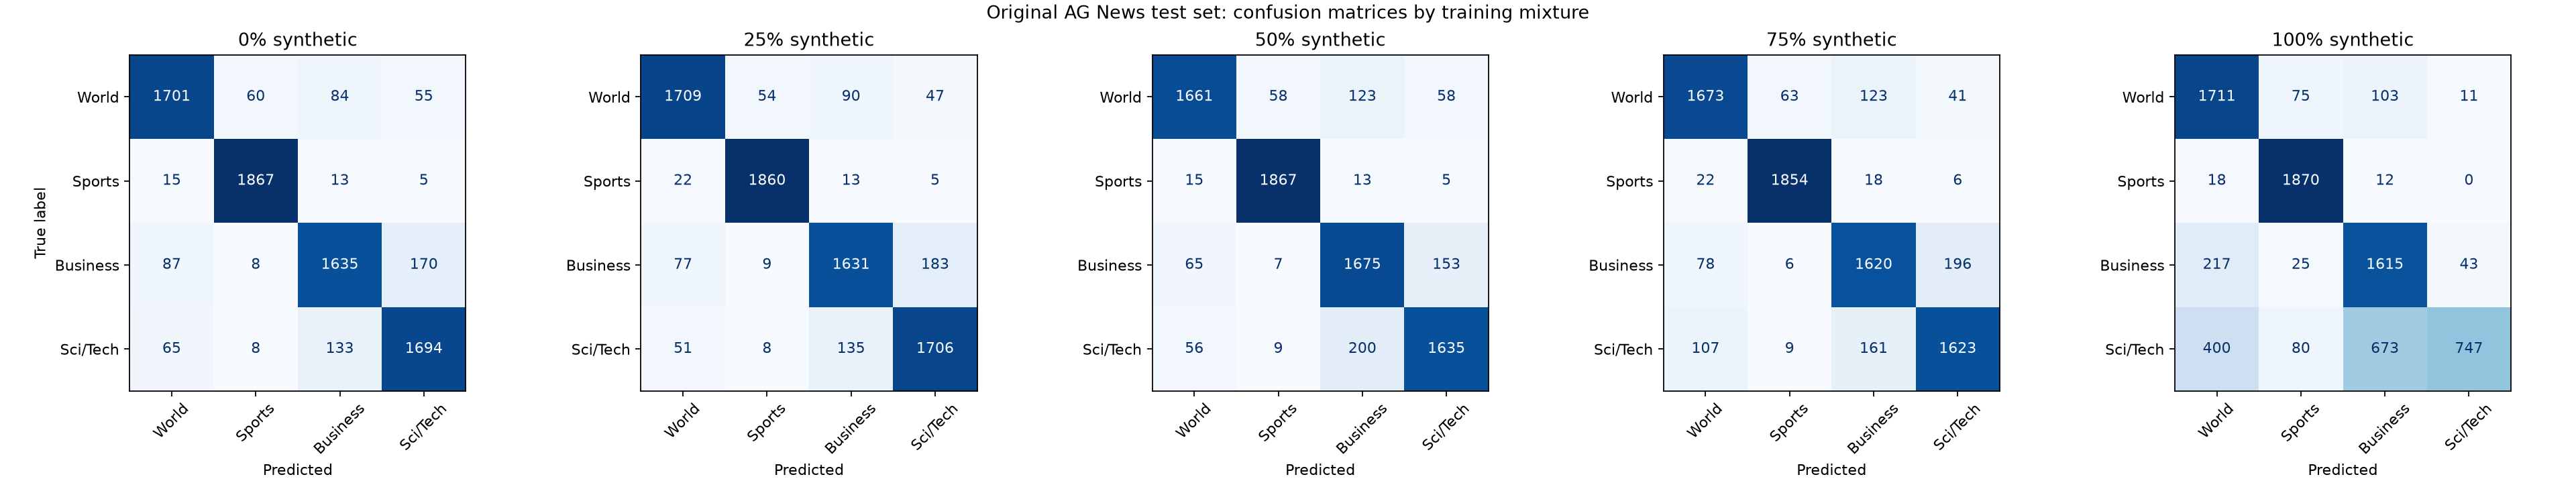

In [5]:
from shutil import copy2
from IPython.display import Image, display

source = SOURCE_DIR / 'mixture_confusion_matrices.png'
target = RESULTS_DIR / 'confusion_matrices.png'
copy2(source, target)
display(Image(filename=str(target)))

## Main findings

- The 25% synthetic mixture has the highest observed test macro F1 (90.85%), only 0.13 percentage points above the 0% real-only run. This single-seed difference is small and should not be treated as conclusive.
- Test macro F1 declines at 50% (89.98%) and 75% (89.06%), then falls to 76.41% with 100% synthetic training data.
- The largest category failure at 100% synthetic is Sci/Tech recall: 39.32%, compared with 89.16% for the real-only run.
- Trainer runtime ranged from about 60 to 68 seconds per run, including validation checks. Peak GPU memory was not recorded during training and cannot be recovered from the saved metrics.